<a href="https://colab.research.google.com/github/ML-HW-SYS/a4-AaronGoldblatt/blob/main/3-svd_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Mount google drive
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
# Make sure your token is stored in a txt file at the location below.
# This way there is no risk that you will push it to your repo
# Never share your token with anyone, it is basically your github password!
with open('/content/gdrive/MyDrive/ece5545/token.txt') as f:
    token = f.readline().strip()
# Use another file to store your github username
with open('/content/gdrive/MyDrive/ece5545/git_username.txt') as f:
    handle = f.readline().strip()

In [3]:
# Clone your github repo
YOUR_TOKEN = token
YOUR_HANDLE = handle
BRANCH = "main"

%mkdir /content/gdrive/MyDrive/ece5545
%cd /content/gdrive/MyDrive/ece5545
!git clone https://{YOUR_TOKEN}@github.com/ML-HW-SYS/a4-{YOUR_HANDLE}.git
%cd /content/gdrive/MyDrive/ece5545/a4-{YOUR_HANDLE}
!git checkout {BRANCH}
!git pull

PROJECT_ROOT = f"/content/gdrive/MyDrive/ece5545/a4-{YOUR_HANDLE}"

mkdir: cannot create directory ‘/content/gdrive/MyDrive/ece5545’: File exists
/content/gdrive/MyDrive/ece5545
fatal: destination path 'a4-AaronGoldblatt' already exists and is not an empty directory.
/content/gdrive/MyDrive/ece5545/a4-AaronGoldblatt
Already on 'main'
Your branch is up to date with 'origin/main'.
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 9 (delta 3), reused 7 (delta 3), pack-reused 2 (from 1)
Unpacking objects: 100% (9/9), 794.22 KiB | 981.00 KiB/s, done.
From https://github.com/ML-HW-SYS/a4-AaronGoldblatt
   5166176..d9a1dc2  main       -> origin/main
Updating 5166176..d9a1dc2
Fast-forward
 1-numerical_precision.ipynb | 941 +++++++++++++++++++++++++++++---------------
 3-svd_mnist.ipynb           | 418 +++++++++++---------
 2 files changed, 868 insertions(+), 491 deletions(-)


In [4]:
# This extension reloads all imports before running each cell
%load_ext autoreload
%autoreload 2

In [5]:
!ls {PROJECT_ROOT}


1-numerical_precision.ipynb	 svd_combined_error_plot.png
2-svd_rank.ipynb		 svd_errors_by_rank_and_precision.png
3-svd_mnist.ipynb		 svd_net.py
comparison_errors_log_scale.png  svd_rank_Cat_Image.png
comparison_errors.png		 svd_rank_MNIST_Activations.png
data				 svd_rank_MNIST_Batch.png
fft_error_log_plot.png		 svd_rank_Neural_Network_Weights.png
im2col_error_log_plot.png	 svd_rank_Random_Matrix.png
logmatmul_error_log_plot.png	 svd_speedup_mnist_act_weight_combined_log.png
mnist.py			 svd_speedup_mnist_act_weight_combined.png
__pycache__			 svd_speedup_mnist_act_weight.png
README.md			 tests
src				 winograd_error_plots.png


In [8]:
# Install required packgaes
!pip install torch numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 104.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 68.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitl

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import time
from torchvision import datasets, transforms
from mnist import Net, SvdLinear, test, compress_weights_svd

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
model = Net().to(device)
model.load_state_dict(torch.load("data/mnist_fc.pt"))

Device: cuda


<All keys matched successfully>

In [11]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
test_dataset = datasets.MNIST(
    'data',
    train=False,
    download=True,
    transform=transform
)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1000)

In [12]:
runtimes = []
accuracies = []
compression_ratios = []

fc1_compression_factor_start = 64
fc1_compression_factor_end = 4
fc1_step = 32

fc1_start_rank = model.fc1.weight.size(1) // fc1_compression_factor_start
fc1_end_rank = model.fc1.weight.size(1) // fc1_compression_factor_end

fc2_compression_factor_start = 100
fc2_compression_factor_end = 4
fc2_step = 15

fc2_start_rank = model.fc2.weight.size(1) // fc2_compression_factor_start
fc2_end_rank = model.fc2.weight.size(1) // fc2_compression_factor_end

for rank_fc1 in range(fc1_start_rank, fc1_end_rank + 1, fc1_step):
    for rank_fc2 in range(fc2_start_rank, fc2_end_rank + 1, fc2_step):
        model_for_svd = Net().to(device)
        model_for_svd.load_state_dict(model.state_dict())

        model_for_svd.fc1 = SvdLinear(model_for_svd.fc1, rank_fc1)
        model_for_svd.fc2 = SvdLinear(model_for_svd.fc2, rank_fc2)

        start = time.time()
        correct_classification = test(
            model_for_svd,
            device,
            test_loader
        )
        end = time.time()
        runtime = end - start

        runtimes.append(runtime)
        accuracy = (
            100.0
            * (
                correct_classification
                / len(test_loader.dataset)
            )
        )
        accuracies.append(accuracy)

        fc1_original_size = model.fc1.weight.numel()
        fc2_original_size = model.fc2.weight.numel()
        total_original_size = fc1_original_size + fc2_original_size

        fc1_compressed_size = (
            rank_fc1
            * (
                model.fc1.weight.size(1)
                + model.fc1.weight.size(0)
            )
        )
        fc2_compressed_size = (
            rank_fc2
            * (
                model.fc2.weight.size(1)
                + model.fc2.weight.size(0)
            )
        )
        total_compressed_size = (
            fc1_compressed_size
            + fc2_compressed_size
        )

        ratio = total_original_size / total_compressed_size
        compression_ratios.append(ratio)

        print(f'Accuracy: {accuracy:.2f}%; Compression Ratio: {ratio:.2f}; Runtime: {runtime:.2f}s')



Test set: Average loss: 1.2805, Accuracy: 6755/10000 (68%)

Accuracy: 67.55%; Compression Ratio: 24.90; Runtime: 2.18s

Test set: Average loss: 0.7233, Accuracy: 8451/10000 (85%)

Accuracy: 84.51%; Compression Ratio: 16.47; Runtime: 1.79s

Test set: Average loss: 0.7104, Accuracy: 8485/10000 (85%)

Accuracy: 84.85%; Compression Ratio: 12.30; Runtime: 2.38s

Test set: Average loss: 0.7175, Accuracy: 8474/10000 (85%)

Accuracy: 84.74%; Compression Ratio: 9.82; Runtime: 2.41s

Test set: Average loss: 0.7221, Accuracy: 8472/10000 (85%)

Accuracy: 84.72%; Compression Ratio: 8.17; Runtime: 2.50s

Test set: Average loss: 0.7179, Accuracy: 8472/10000 (85%)

Accuracy: 84.72%; Compression Ratio: 7.00; Runtime: 2.13s

Test set: Average loss: 0.7173, Accuracy: 8478/10000 (85%)

Accuracy: 84.78%; Compression Ratio: 6.12; Runtime: 1.82s

Test set: Average loss: 0.7178, Accuracy: 8476/10000 (85%)

Accuracy: 84.76%; Compression Ratio: 5.43; Runtime: 2.14s

Test set: Average loss: 0.7162, Accuracy: 84

In [13]:
indices = np.argsort(compression_ratios)
sorted_compression_ratios = [compression_ratios[i] for i in indices]
sorted_accuracies = [accuracies[i] for i in indices]
sorted_runtimes = [runtimes[i] for i in indices]

In [14]:
def smooth(data, window_size=20):
    cumulative_sum = [0]
    for idx, x in enumerate(data, 1):
        cumulative_sum.append(cumulative_sum[idx - 1] + x)

    smooth_data = []
    for idx in range(len(data) - window_size + 1):
        smooth_data.append(
            (
                cumulative_sum[idx + window_size]
                - cumulative_sum[idx]
            )
            / window_size
        )

    return smooth_data

In [15]:
compression_ratios_smoothed = smooth(sorted_compression_ratios)
accuracies_smoothed = smooth(sorted_accuracies)
runtimes_smoothed = smooth(sorted_runtimes)

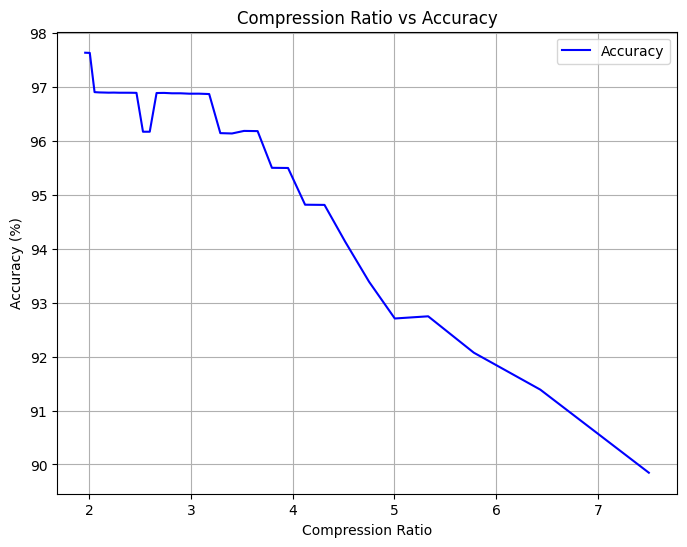

In [16]:
# Plot 1: Compression Ratio vs Accuracy
plt.figure(figsize=(8, 6))
plt.plot(compression_ratios_smoothed, accuracies_smoothed, 'b-', label='Accuracy')
plt.xlabel('Compression Ratio')
plt.ylabel('Accuracy (%)')
plt.title('Compression Ratio vs Accuracy')
plt.grid(True)
plt.legend()
plt.show()

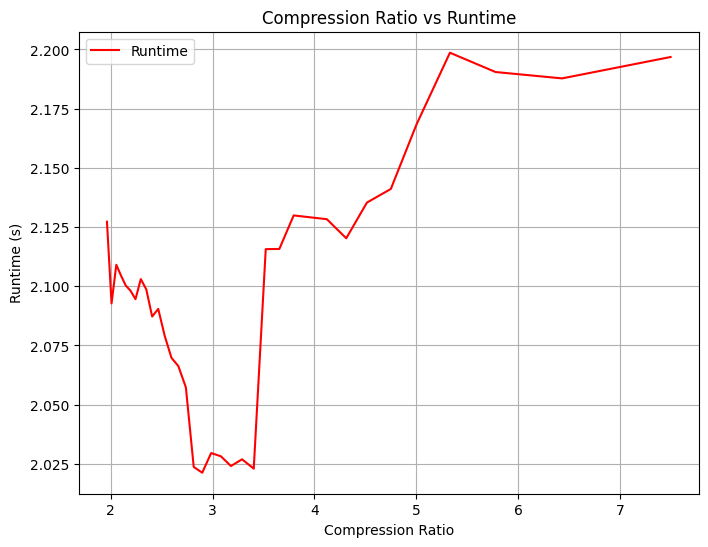

In [17]:
# Plot 2: Compression Ratio vs Runtime
plt.figure(figsize=(8, 6))
plt.plot(compression_ratios_smoothed, runtimes_smoothed, 'r-', label='Runtime')
plt.xlabel('Compression Ratio')
plt.ylabel('Runtime (s)')
plt.title('Compression Ratio vs Runtime')
plt.grid(True)
plt.legend()
plt.show()

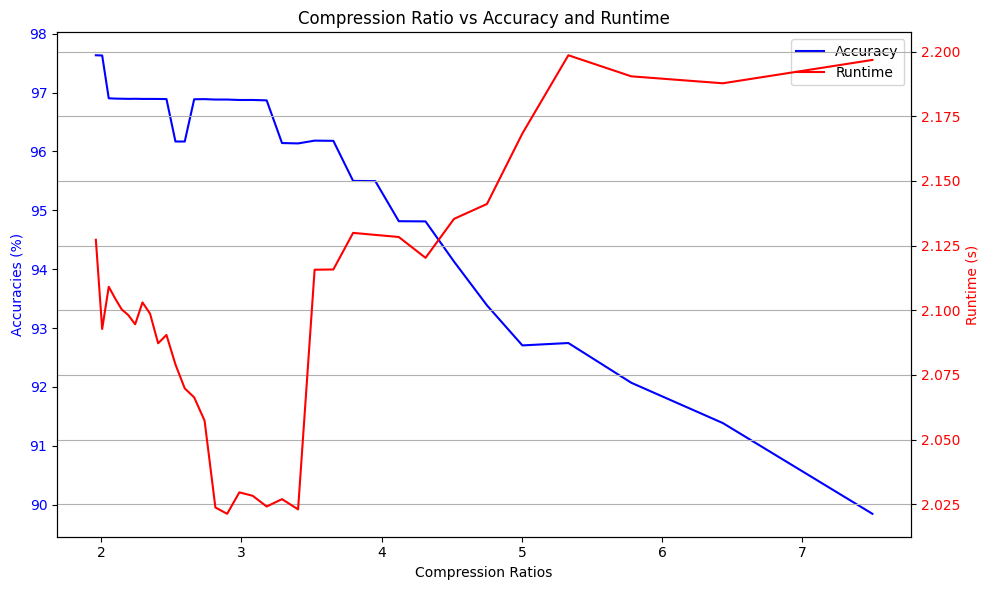

In [18]:
# Plot 3: Compression Ratio vs Accuracy and Runtime (with dual y-axes)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Accuracy on the left y-axis (blue)
ax1.set_xlabel('Compression Ratios')
ax1.set_ylabel('Accuracies (%)', color='blue')
ax1.plot(compression_ratios_smoothed, accuracies_smoothed, 'b-', label='Accuracy')
ax1.tick_params(axis='y', labelcolor='blue')

# Create a second y-axis for Runtime
ax2 = ax1.twinx()
ax2.set_ylabel('Runtime (s)', color='red')
ax2.plot(compression_ratios_smoothed, runtimes_smoothed, 'r-', label='Runtime')
ax2.tick_params(axis='y', labelcolor='red')

# Add grid
plt.grid(True)
plt.title('Compression Ratio vs Accuracy and Runtime')

# Add legend with both lines
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')

# Adjust layout to prevent clipping of labels
fig.tight_layout()

plt.show()

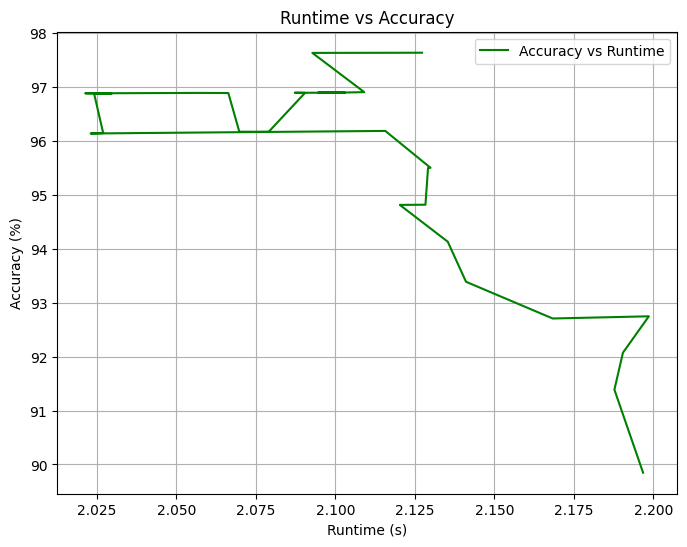

In [19]:
# Plot 3: Runtime vs Accuracy
plt.figure(figsize=(8, 6))
plt.plot(runtimes_smoothed, accuracies_smoothed, 'g-', label='Accuracy vs Runtime')
plt.xlabel('Runtime (s)')
plt.ylabel('Accuracy (%)')
plt.title('Runtime vs Accuracy')
plt.grid(True)
plt.legend()
plt.show()